# Gene-wise variance concordance across slices and cell types
For every annotated Xenium slice, compare raw, Syndri-filtered, and SPLIT within-cell-type gene-variance profiles with the scRNA-seq reference.

In [113]:
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import seaborn as sns
from scipy.stats import spearmanr

RESULTS_DIR = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/results/final')
REFERENCE_PATH = Path('/work/magroup/skrieger/Syndri/data/datasets/breast_xenium/interim/single-cell/breast_cancer_chromium_genesubset.h5ad')
SLICE_PATTERN = '*_rctd_annotated.h5ad'
# Match the threshold-selection strategies used by eval/metrics_eval.py.
# Choose 'fixed_probability' or 'target_removed_fraction'. Lists may contain one or many values.
THRESHOLD_SELECTION = 'target_removed_fraction'
FIXED_PROBABILITY_THRESHOLDS = [0.99,0.95,0.9,0.8,0.7,0.6,0.5]
TARGET_REMOVED_FRACTIONS = [0.5,0.6,0.7,0.8,0.9]
CELL_TYPE_SPECIFIC_REMOVAL = True  # True selects a separate threshold within each spatial cell type
MIN_ST_CELLS = 50
MIN_SC_CELLS = 50
MIN_REF_DETECTION = 0.05

slice_paths = sorted(RESULTS_DIR.glob(SLICE_PATTERN))
if not slice_paths:
    raise FileNotFoundError(f'No files matching {SLICE_PATTERN!r} in {RESULTS_DIR}')
print(f'Found {len(slice_paths)} slices')
[path.name for path in slice_paths]

Found 19 slices


['GSM9509156_breast_breast_B17_B17_rctd_annotated.h5ad',
 'GSM9509157_breast_breast_B16_B16_rctd_annotated.h5ad',
 'GSM9509158_breast_breast_B15_B15_rctd_annotated.h5ad',
 'GSM9509159_breast_breast_B14_B14_rctd_annotated.h5ad',
 'GSM9509160_breast_breast_B2_B2_rctd_annotated.h5ad',
 'GSM9509161_breast_breast_B13_B13_rctd_annotated.h5ad',
 'GSM9509162_breast_breast_B12_B12_rctd_annotated.h5ad',
 'GSM9509163_breast_breast_B11_B11_rctd_annotated.h5ad',
 'GSM9509164_breast_breast_B10_B10_rctd_annotated.h5ad',
 'GSM9509165_breast_breast_B4_B4_rctd_annotated.h5ad',
 'GSM9509166_breast_breast_B9_B9_rctd_annotated.h5ad',
 'GSM9509167_breast_breast_B8_B8_rctd_annotated.h5ad',
 'GSM9509168_breast_breast_B7_B7_rctd_annotated.h5ad',
 'GSM9509169_breast_breast_B6_B6_rctd_annotated.h5ad',
 'GSM9509170_breast_breast_B3_B3_rctd_annotated.h5ad',
 'GSM9509171_breast_breast_B5_B5_rctd_annotated.h5ad',
 'GSM9509172_breast_breast_B1_B1_1_rctd_annotated.h5ad',
 'GSM9509173_breast_breast_B1_B1_2_rctd_annotat

In [114]:
def to_csr(X):
    if sp.issparse(X):
        return X.tocsr().astype(np.float32)
    return sp.csr_matrix(np.asarray(X, dtype=np.float32))

def normalize_log1p(X, target_sum=1e4):
    X = to_csr(X).copy()
    totals = np.asarray(X.sum(axis=1)).ravel()
    scale = np.divide(target_sum, totals, out=np.zeros_like(totals, dtype=np.float32), where=totals > 0)
    X = sp.diags(scale) @ X
    X.data = np.log1p(X.data)
    return X.tocsr()

def sparse_gene_variance(X):
    X = to_csr(X)
    mean = np.asarray(X.mean(axis=0)).ravel()
    mean_sq = np.asarray(X.power(2).mean(axis=0)).ravel()
    return np.maximum(mean_sq - mean**2, 0)

def expressed_counts_and_probabilities(X, probabilities):
    X = to_csr(X)
    rows, cols = X.nonzero()
    counts = X.data.astype(float)
    pvals = np.asarray(probabilities[rows, cols]).ravel().astype(float)
    good = np.isfinite(pvals) & np.isfinite(counts) & (counts > 0)
    return counts[good], pvals[good]

def threshold_for_removed_fraction(probabilities, X, target_removed_fraction):
    # Count-weighted selection, identical to eval/metrics_eval.py.
    target_removed_fraction = float(target_removed_fraction)
    if not 0 <= target_removed_fraction <= 1:
        raise ValueError('Target removed fractions must be between 0 and 1')
    if target_removed_fraction == 0:
        return np.inf, 0.0
    if target_removed_fraction == 1:
        return -np.inf, 1.0
    counts, pvals = expressed_counts_and_probabilities(X, probabilities)
    if counts.size == 0:
        raise ValueError('No expressed transcripts found (X > 0)')
    order = np.argsort(pvals)[::-1]
    p_sorted, c_sorted = pvals[order], counts[order]
    index = min(int(np.searchsorted(np.cumsum(c_sorted), target_removed_fraction * counts.sum(), side='left')), len(p_sorted) - 1)
    threshold = float(p_sorted[index])
    achieved = float(c_sorted[p_sorted >= threshold].sum() / counts.sum())
    return threshold, achieved

def zero_counts_at_thresholds(X, probabilities, row_thresholds):
    cleaned = to_csr(X).copy()
    rows, cols = cleaned.nonzero()
    pvals = np.asarray(probabilities[rows, cols]).ravel()
    thresholds = np.asarray(row_thresholds)
    if thresholds.ndim == 0:
        thresholds = np.full(cleaned.shape[0], float(thresholds))
    cleaned.data[pvals >= thresholds[rows]] = 0
    cleaned.eliminate_zeros()
    return cleaned

def make_syndri_cases(X, probabilities, labels):
    if THRESHOLD_SELECTION == 'fixed_probability':
        settings = [('fixed_probability', value) for value in FIXED_PROBABILITY_THRESHOLDS]
    elif THRESHOLD_SELECTION == 'target_removed_fraction':
        settings = [('target_removed_fraction', value) for value in TARGET_REMOVED_FRACTIONS]
    else:
        raise ValueError("THRESHOLD_SELECTION must be 'fixed_probability' or 'target_removed_fraction'")

    cases = []
    for selection, value in settings:
        group_thresholds = {}
        if selection == 'fixed_probability':
            threshold, achieved = float(value), np.nan
            row_thresholds = threshold
            label = f'Syndri (p >= {threshold:g})'
        elif CELL_TYPE_SPECIFIC_REMOVAL:
            row_thresholds = np.full(X.shape[0], np.inf)
            for cell_type in pd.unique(labels):
                mask = labels == cell_type
                threshold, _ = threshold_for_removed_fraction(probabilities[mask], X[mask], value)
                row_thresholds[mask] = threshold
                group_thresholds[str(cell_type)] = threshold
            threshold, achieved = np.nan, float(value)
            label = f'Syndri (cell-type remove {value:g})'
        else:
            threshold, achieved = threshold_for_removed_fraction(probabilities, X, value)
            row_thresholds = threshold
            label = f'Syndri (remove {value:g})'
        cleaned = zero_counts_at_thresholds(X, probabilities, row_thresholds)
        total_counts = float(X.sum())
        achieved = float((total_counts - cleaned.sum()) / total_counts) if total_counts > 0 else np.nan
        cases.append((label, cleaned, {'threshold_selection': selection, 'threshold_setting': value, 'admix_prob_threshold': threshold, 'achieved_removed_fraction': achieved, 'group_admix_prob_thresholds': group_thresholds}))
    return cases

def slice_id_from_path(path):
    return path.name.removesuffix('_rctd_annotated.h5ad')

In [115]:
sc_data = ad.read_h5ad(REFERENCE_PATH)
if 'SoupX' not in sc_data.layers or 'cell_type' not in sc_data.obs:
    raise KeyError("Reference requires layers['SoupX'] and obs['cell_type']")
sc_gene_names = sc_data.var_names.astype(str)
sc_gene_to_idx = {gene: i for i, gene in enumerate(sc_gene_names)}
sc_labels = sc_data.obs['cell_type'].astype(str).to_numpy()
sc_types = set(sc_labels)
sc_data

AnnData object with n_obs × n_vars = 10658 × 277
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sample_id', 'percent_mt', 'percent_ribo', 'percent_hb', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'SCT_snn_res.0.5', 'SCT_snn_res.0.4', 'SCT_snn_res.2', 'donor_id', 'nCount_SoupX', 'nFeature_SoupX', 'Harmonised_Level4', 'Level3', 'Level2', 'Level1', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'tissue_type', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'assay_ontology_term_id', 'suspension_type', 'input_material', 'histology', 'sample_type', 'histology_immune', 'DV200_percent', 'block_age_months', 'is_primary_data', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns:

In [ ]:
variance_rows = []
comparison_rows = []

for slice_number, slice_path in enumerate(slice_paths, start=1):
    slice_id = slice_id_from_path(slice_path)
    print(f'[{slice_number:02d}/{len(slice_paths):02d}] {slice_id}')
    st_data = ad.read_h5ad(slice_path)
    required_layers = {'split_purified_counts_X', 'syndri_admix_probs_X'}
    missing_layers = required_layers - set(st_data.layers)
    if missing_layers or 'harmony_cell_type' not in st_data.obs:
        raise KeyError(f"{slice_path.name}: missing layers {sorted(missing_layers)} or obs['harmony_cell_type']")
    st_gene_names = st_data.var_names.astype(str)
    common_genes = sorted(set(st_gene_names) & set(sc_gene_names))
    if not common_genes:
        raise ValueError(f'{slice_path.name}: no genes overlap the reference')
    st_gene_to_idx = {gene: i for i, gene in enumerate(st_gene_names)}
    st_idx = np.array([st_gene_to_idx[g] for g in common_genes])
    sc_idx = np.array([sc_gene_to_idx[g] for g in common_genes])
    X_raw = to_csr(st_data.X[:, st_idx])
    X_split = to_csr(st_data.layers['split_purified_counts_X'][:, st_idx])
    P = st_data.layers['syndri_admix_probs_X'][:, st_idx]
    P = P.toarray() if sp.issparse(P) else np.asarray(P)
    X_ref = to_csr(sc_data.layers['SoupX'][:, sc_idx])
    st_labels = st_data.obs['harmony_cell_type'].astype(str).to_numpy()
    syndri_cases = make_syndri_cases(X_raw, P, st_labels)
    empty_selection = {'threshold_selection': 'none', 'threshold_setting': np.nan, 'admix_prob_threshold': np.nan, 'achieved_removed_fraction': np.nan, 'group_admix_prob_thresholds': {}}
    method_cases = [('Raw', X_raw, empty_selection), *syndri_cases, ('SPLIT', X_split, empty_selection)]
    method_matrices = [(method, normalize_log1p(matrix), metadata) for method, matrix, metadata in method_cases]
    X_ref_norm = normalize_log1p(X_ref)
    common_cell_types = sorted(set(st_labels) & sc_types)
    for cell_type in common_cell_types:
        st_mask = st_labels == cell_type
        sc_mask = sc_labels == cell_type
        n_st, n_sc = int(st_mask.sum()), int(sc_mask.sum())
        base = {'slice': slice_id, 'slice_path': str(slice_path), 'cell_type': cell_type, 'n_spatial_cells': n_st, 'n_reference_cells': n_sc}
        if n_st < MIN_ST_CELLS or n_sc < MIN_SC_CELLS:
            comparison_rows.append({**base, 'method': pd.NA, 'spearman_rho': np.nan, 'p_value': np.nan, 'n_genes': 0, 'status': 'insufficient_cells'})
            continue
        var_ref = sparse_gene_variance(X_ref_norm[sc_mask])
        ref_detection = np.asarray((X_ref[sc_mask] > 0).mean(axis=0)).ravel()
        gene_mask = (ref_detection >= MIN_REF_DETECTION) & (var_ref > 0)
        n_genes = int(gene_mask.sum())
        if n_genes < 2:
            comparison_rows.append({**base, 'method': pd.NA, 'spearman_rho': np.nan, 'p_value': np.nan, 'n_genes': n_genes, 'status': 'insufficient_genes'})
            continue
        kept_genes = np.asarray(common_genes)[gene_mask]
        for method, matrix, selection_metadata in method_matrices:
            values = sparse_gene_variance(matrix[st_mask])
            rho, pval = spearmanr(var_ref[gene_mask], values[gene_mask])
            comparison_rows.append({**base, **selection_metadata, 'method': method, 'spearman_rho': rho, 'p_value': pval, 'n_genes': n_genes, 'status': 'ok'})
            variance_rows.extend({'slice': slice_id, 'cell_type': cell_type, 'gene': gene, 'method': method, **selection_metadata, 'variance': variance, 'reference_variance': ref_variance} for gene, variance, ref_variance in zip(kept_genes, values[gene_mask], var_ref[gene_mask]))
    del st_data, X_raw, X_split, X_ref, X_ref_norm, syndri_cases, method_cases, method_matrices

variance_df = pd.DataFrame(variance_rows)
comparison_df = pd.DataFrame(comparison_rows)
comparison_df.sort_values(['slice', 'cell_type', 'method'], na_position='last').reset_index(drop=True)

[01/19] GSM9509156_breast_breast_B17_B17
[02/19] GSM9509157_breast_breast_B16_B16
[03/19] GSM9509158_breast_breast_B15_B15
[04/19] GSM9509159_breast_breast_B14_B14
[05/19] GSM9509160_breast_breast_B2_B2
[06/19] GSM9509161_breast_breast_B13_B13
[07/19] GSM9509162_breast_breast_B12_B12
[08/19] GSM9509163_breast_breast_B11_B11
[09/19] GSM9509164_breast_breast_B10_B10
[10/19] GSM9509165_breast_breast_B4_B4
[11/19] GSM9509166_breast_breast_B9_B9
[12/19] GSM9509167_breast_breast_B8_B8
[13/19] GSM9509168_breast_breast_B7_B7
[14/19] GSM9509169_breast_breast_B6_B6
[15/19] GSM9509170_breast_breast_B3_B3
[16/19] GSM9509171_breast_breast_B5_B5
[17/19] GSM9509172_breast_breast_B1_B1_1
[18/19] GSM9509173_breast_breast_B1_B1_2
[19/19] GSM9509174_breast_breast_B1_B1_3


,slice,slice_path,cell_type,n_spatial_cells,n_reference_cells,threshold_selection,threshold_setting,admix_prob_threshold,achieved_removed_fraction,group_admix_prob_thresholds,method,spearman_rho,p_value,n_genes,status
0,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,none,NaN,NaN,NaN,{},Raw,0.635916,8.147619e-08,58,ok
1,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,none,NaN,NaN,NaN,{},SPLIT,0.680089,4.316764e-09,58,ok
2,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.5,NaN,0.500006,{'capillary endothelial cell': 0.9209418892860...,Syndri (cell-type remove 0.5),0.651789,2.995729e-08,58,ok
3,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.6,NaN,0.600002,{'capillary endothelial cell': 0.8040032386779...,Syndri (cell-type remove 0.6),0.658248,1.960142e-08,58,ok
4,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.7,NaN,0.700002,{'capillary endothelial cell': 0.5003972649574...,Syndri (cell-type remove 0.7),0.686856,2.630487e-09,58,ok
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1990,GSM9509174_breast_breast_B1_B1_3,/work/magroup/skrieger/Syndri/data/datasets/br...,smooth muscle cell,9260,686,target_removed_fraction,0.5,NaN,0.500001,"{'macrophage': 0.9414076805114746, 'malignant ...",Syndri (cell-type remove 0.5),0.719700,9.202429e-11,60,ok
1991,GSM9509174_breast_breast_B1_B1_3,/work/magroup/skrieger/Syndri/data/datasets/br...,smooth muscle cell,9260,686,target_removed_fraction,0.6,NaN,0.600003,"{'macrophage': 0.8578869104385376, 'malignant ...",Syndri (cell-type remove 0.6),0.775049,3.647574e-13,60,ok
1992,GSM9509174_breast_breast_B1_B1_3,/work/magroup/skrieger/Syndri/data/datasets/br...,smooth muscle cell,9260,686,target_removed_fraction,0.7,NaN,0.700005,"{'macrophage': 0.6863122582435608, 'malignant ...",Syndri (cell-type remove 0.7),0.790942,5.534544e-14,60,ok
1993,GSM9509174_breast_breast_B1_B1_3,/work/magroup/skrieger/Syndri/data/datasets/br...,smooth muscle cell,9260,686,target_removed_fraction,0.8,NaN,0.800003,"{'macrophage': 0.3887166678905487, 'malignant ...",Syndri (cell-type remove 0.8),0.799833,1.792531e-14,60,ok


In [109]:
display(comparison_df.groupby('status').size().rename('rows'))
concordance_df = comparison_df.query("status == 'ok'").copy()
print(f"Calculated {len(concordance_df)} method-level concordances for {concordance_df[['slice', 'cell_type']].drop_duplicates().shape[0]} eligible slice-cell type combinations.")
concordance_df.head(n=10)

status
ok    1995
Name: rows, dtype: int64

Calculated 1995 method-level concordances for 285 eligible slice-cell type combinations.


,slice,slice_path,cell_type,n_spatial_cells,n_reference_cells,threshold_selection,threshold_setting,admix_prob_threshold,achieved_removed_fraction,group_admix_prob_thresholds,method,spearman_rho,p_value,n_genes,status
0,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,none,NaN,NaN,NaN,{},Raw,0.635055,8.588225e-08,58,ok
1,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.5,NaN,0.500006,{'capillary endothelial cell': 0.9209418892860...,Syndri (cell-type remove 0.5),0.649697,3.429383e-08,58,ok
2,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.6,NaN,0.600002,{'capillary endothelial cell': 0.8040032386779...,Syndri (cell-type remove 0.6),0.656710,2.170451e-08,58,ok
3,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.7,NaN,0.700002,{'capillary endothelial cell': 0.5003972649574...,Syndri (cell-type remove 0.7),0.684518,3.126074e-09,58,ok
4,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.8,NaN,0.800006,{'capillary endothelial cell': 0.1554035246372...,Syndri (cell-type remove 0.8),0.704556,6.747047e-10,58,ok
5,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,target_removed_fraction,0.9,NaN,0.900005,{'capillary endothelial cell': 0.0292957238852...,Syndri (cell-type remove 0.9),0.637580,7.356296e-08,58,ok
6,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,"CD4-positive, alpha-beta memory T cell",506,252,none,NaN,NaN,NaN,{},SPLIT,0.677382,5.243545e-09,58,ok
7,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,capillary endothelial cell,2525,582,none,NaN,NaN,NaN,{},Raw,0.417006,2.424560e-04,73,ok
8,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,capillary endothelial cell,2525,582,target_removed_fraction,0.5,NaN,0.500006,{'capillary endothelial cell': 0.9209418892860...,Syndri (cell-type remove 0.5),0.734358,1.431876e-13,73,ok
9,GSM9509156_breast_breast_B17_B17,/work/magroup/skrieger/Syndri/data/datasets/br...,capillary endothelial cell,2525,582,target_removed_fraction,0.6,NaN,0.600002,{'capillary endothelial cell': 0.8040032386779...,Syndri (cell-type remove 0.6),0.794234,5.115827e-17,73,ok


In [110]:
def add_sig_bar(ax, x1, x2, y, h, text, fontsize=8):
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        lw=0.9,
        c="black",
        clip_on=False,
    )
    ax.text(
        (x1 + x2) / 2,
        y + h,
        text,
        ha="center",
        va="bottom",
        fontsize=fontsize,
    )

/tmp/ipykernel_329761/2056378646.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


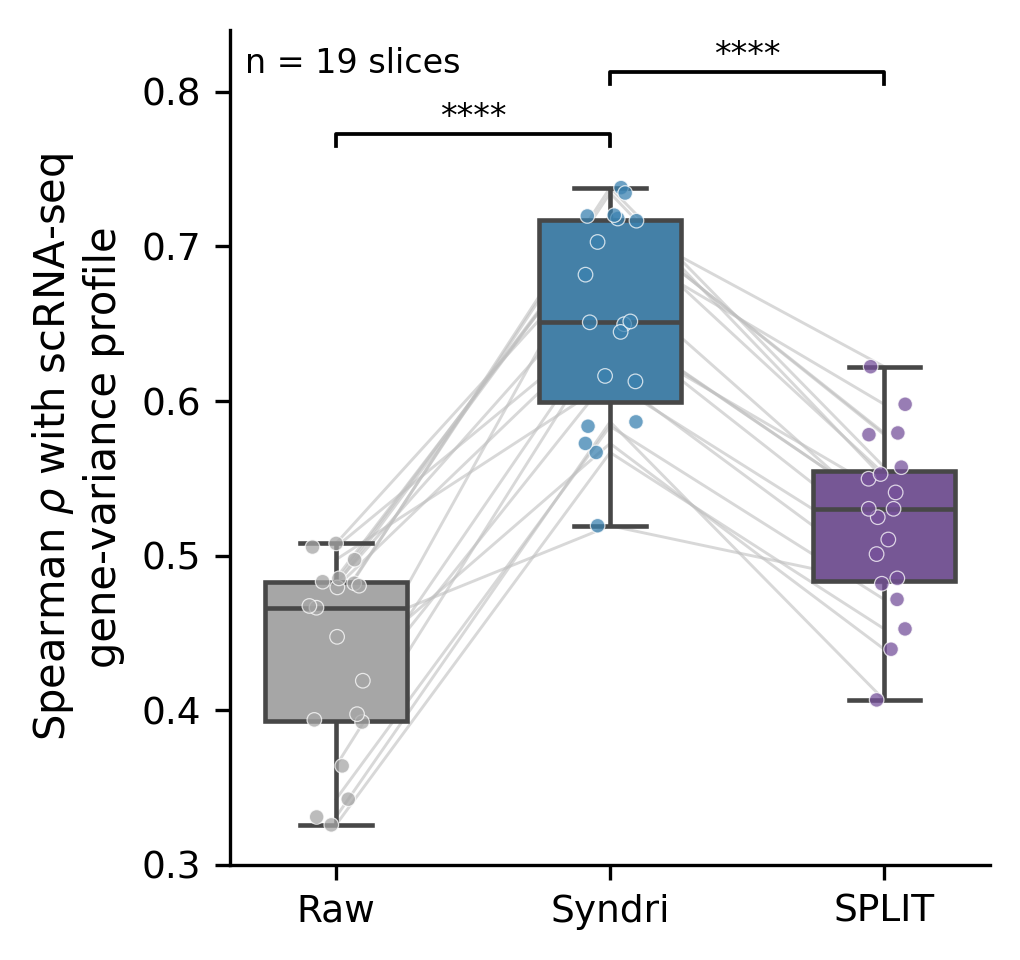

In [111]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# Clean method names
# ------------------------------------------------------------

method_map = {
    "Raw": "Raw",
    "Syndri (cell-type remove 0.5)": "Syndri",
    "SPLIT": "SPLIT",
}

plot_df = concordance_df.copy()
plot_df['sample_id'] = plot_df['slice'].copy()
plot_df["method_plot"] = plot_df["method"].map(method_map)

method_order = ["Raw", "Syndri", "SPLIT"]

# ------------------------------------------------------------
# Main-text analysis unit = tissue slice
#
# Each slice contributes one value per method:
# median correlation across its eligible cell types.
# ------------------------------------------------------------

slice_df = (
    plot_df
    .dropna(subset=["method_plot"])
    .groupby(
        ["sample_id", "method_plot"],
        observed=True
    )["spearman_rho"]
    .median()
    .reset_index()
)

# Only retain slices represented for all three methods
wide = (
    slice_df
    .pivot(
        index="sample_id",
        columns="method_plot",
        values="spearman_rho"
    )
    .dropna(subset=method_order)
)

slice_df = (
    wide[method_order]
    .reset_index()
    .melt(
        id_vars="sample_id",
        var_name="method_plot",
        value_name="spearman_rho"
    )
)

# ------------------------------------------------------------
# Colors
# ------------------------------------------------------------

palette = {
    "Raw": "#A6A6A6",
    "Syndri": "#3B82B0",
    "SPLIT": "#76519B",
}

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(3.5, 3.3), dpi=300)

# Paired slice trajectories
for sample_id, df in slice_df.groupby("sample_id", observed=True):

    y = (
        df.set_index("method_plot")
        .reindex(method_order)["spearman_rho"]
        .to_numpy()
    )

    ax.plot(
        np.arange(3),
        y,
        color="0.75",
        linewidth=0.7,
        alpha=0.6,
        zorder=1,
    )

# Distribution
sns.boxplot(
    data=slice_df,
    x="method_plot",
    y="spearman_rho",
    order=method_order,
    palette=palette,
    width=0.52,
    linewidth=1.1,
    saturation=0.85,
    showfliers=False,
    ax=ax,
    zorder=2,
)

# Individual tissue slices
sns.stripplot(
    data=slice_df,
    x="method_plot",
    y="spearman_rho",
    order=method_order,
    hue="method_plot",
    palette=palette,
    jitter=0.10,
    size=3.5,
    alpha=0.75,
    edgecolor="white",
    linewidth=0.3,
    legend=False,
    ax=ax,
    zorder=3,
)
# Give the bars some vertical room
ax.set_ylim(0.30, 0.84)

add_sig_bar(ax, 0, 1, 0.765, 0.008, "****")
add_sig_bar(ax, 1, 2, 0.805, 0.008, "****")

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.set_xlabel("")

ax.set_ylabel(
    r"Spearman $\rho$ with scRNA-seq"
    "\ngene-variance profile"
)

# ax.set_title(
#     "Within-cell-type gene-variance concordance",
#     fontsize=12,
#     pad=8
# )

# ax.set_ylim(0.30, 0.76)

# Remove zero line
# ax.axhline(...)

ax.text(
    0.02, 0.98,
    f"n = {wide.shape[0]} slices",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=8
)


ax.tick_params(
    axis="both",
    labelsize=9,
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

sns.despine(ax=ax)

fig.tight_layout()

plt.show()

### Wilcoxon Test

In [112]:
from scipy.stats import wilcoxon

# Paired tests across tissue slices
p_raw = wilcoxon(
    wide["Syndri"],
    wide["Raw"],
    alternative="two-sided",
).pvalue

p_split = wilcoxon(
    wide["Syndri"],
    wide["SPLIT"],
    alternative="two-sided",
).pvalue

print("Syndri vs Raw:", p_raw)
print("Syndri vs SPLIT:", p_split)
import numpy as np
from scipy.stats import rankdata

# Paired differences across the 19 slices
d_raw = wide["Syndri"] - wide["Raw"]
d_split = wide["Syndri"] - wide["SPLIT"]

print("Syndri vs Raw")
print("Median Δrho:", np.median(d_raw))
print("Mean Δrho:", np.mean(d_raw))
print("IQR:", np.percentile(d_raw, [25, 75]))

print("\nSyndri vs SPLIT")
print("Median Δrho:", np.median(d_split))
print("Mean Δrho:", np.mean(d_split))
print("IQR:", np.percentile(d_split, [25, 75]))


Syndri vs Raw: 3.814697265625e-06
Syndri vs SPLIT: 3.814697265625e-06
Syndri vs Raw
Median Δrho: 0.23709711661184385
Mean Δrho: 0.21673747678704675
IQR: [0.18261471 0.25707736]

Syndri vs SPLIT
Median Δrho: 0.13096629503615193
Mean Δrho: 0.13020489603583818
IQR: [0.11186506 0.14943949]
